<a href="https://colab.research.google.com/github/LACDR-CDS/SCDR_RNAseq/blob/main/Session3and4/group6_solution_TBX5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Session 3 & 4
In the last session, you learned the basic processing steps for RNA sequencing data. Now you will do the next steps in the analysis of transcriptomics data to investigate the transcriptional impact of TBX5 on human cardiomyocyte differentiation.

## Background
Human induced pluripotent stem cell-derived cardiomyocytes (hiPSC-CMs) are widely used for disease modeling and therapeutic testing, but their immaturity and heterogeneity remain major limitations. Previous studies have shown that distinct single-cell populations emerge during differentiation, characterized by unique transcriptional regulators. Experimental perturbations in hiPSC-CMs have revealed that TBX5 gain- or loss-of-function reshapes gene networks.

In this practical, you will compare the effect of TBX5 gain-of-function (overexpression: tbx5-oe) and/or TBX5 loss-of-function (CRISPR genome editing: tbx5-ge) with a control (tbx5).

## Objectives  
1. Explore global gene expression changes (PCA) across TBX5 conditions.
2. Identify differentially expressed genes (DEGs) specific to TBX5 perturbations.  
3. Visualize DEGs with volcano plots and heatmaps.  
4. Perform GO enrichment to determine affected biological pathways.  
5. Interpret whether down- and upregulation of TBX5 leads to loss/gain of cardiomyocyte identity and/or loss/gain of non-cardiac programs.  

## Setup

Run the following cells to set up the necessary packages and download the data. If you wish to use a package which is not in the list below, you will need to install and import it yourself.

In [ ]:
#Install packages which are not in the default environment
%pip install scanpy
%pip install pydeseq2
%pip install gseapy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.2/174.2 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 284.1/284.1 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.6/87.6 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 605.3/605.3 kB 5.1 MB/s eta 0:00:00


In [ ]:
#Import packages
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scanpy as sc
import anndata as ad
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
import pickle
import gseapy
import os
import warnings
warnings.filterwarnings("ignore")

In [ ]:
group_number = 6

#Make data directory if it does not exist
os.makedirs("data", exist_ok=True)
os.makedirs("plots", exist_ok=True)

#Download datasets in the data folder
!wget https://raw.githubusercontent.com/LACDR-CDS/SCDR_Bioinformatics_Practical/refs/heads/main/Session3and4/data/group{group_number}_counts.txt -O data/group{group_number}_counts.txt
!wget https://raw.githubusercontent.com/LACDR-CDS/SCDR_Bioinformatics_Practical/refs/heads/main/Session3and4/data/group{group_number}_metadata.csv -O data/group{group_number}_metadata.csv

--2026-01-13 22:52:33--  https://raw.githubusercontent.com/LACDR-CDS/SCDR_Bioinformatics_Practical/refs/heads/main/Session3and4/data/group6_counts.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1134370 (1.1M) [text/plain]
Saving to: ‘data/group6_counts.txt’

data/group6_counts. 100%[===================>]   1.08M  --.-KB/s    in 0.1s    

2026-01-13 22:52:34 (9.27 MB/s) - ‘data/group6_counts.txt’ saved [1134370/1134370]

--2026-01-13 22:52:34--  https://raw.githubusercontent.com/LACDR-CDS/SCDR_Bioinformatics_Practical/refs/heads/main/Session3and4/data/group6_metadata.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.c

## Data import
Read in your counts and metadata table like you learned in session 2.
- How many samples and genes do you have?

Read the corresponding metadata table.
- Which differentiation day do the samples belong to?

**Solution**<br/>
There are 6 samples (2 control, 2 overexpressed, 2 gene-edited/downregulated) and 42844 genes. The samples belong to differentiation day 30.

### ANSWER CODE

In [ ]:
# Load data
counts = pd.read_csv("data/group6_counts.txt", sep="\t", index_col=0)
metadata = pd.read_csv("data/group6_metadata.csv")
metadata.index=metadata['sample_id']
print(counts)
metadata

             day30_rep1_tbx5_ge  day30_rep2_tbx5_ge  day30_rep1_tbx5  \
DDX11L1                       1                   0                0   
WASH7P                      356                 374              420   
MIR6859-1                     2                   4                1   
MIR1302-2HG                   0                   0                0   
MIR1302-2                     0                   0                0   
...                         ...                 ...              ...   
ND6                        7799                4372            28668   
TRNE                          0                   0                0   
CYTB                      27095               16652            63935   
TRNT                          0                   0                0   
TRNP                        209                 242              969   

             day30_rep2_tbx5  day30_rep1_tbx5_oe  day30_rep2_tbx5_oe  
DDX11L1                    0                   0                

,sample_id,day,replicate,stage,cell line,condition
sample_id,,,,,,
day30_rep1_tbx5_ge,day30_rep1_tbx5_ge,30.0,1,cardiomyocyte,hiPSC,tbx5_ge
day30_rep2_tbx5_ge,day30_rep2_tbx5_ge,30.0,2,cardiomyocyte,hiPSC,tbx5_ge
day30_rep1_tbx5,day30_rep1_tbx5,30.0,1,cardiomyocyte,hiPSC,tbx5
day30_rep2_tbx5,day30_rep2_tbx5,30.0,2,cardiomyocyte,hiPSC,tbx5
day30_rep1_tbx5_oe,day30_rep1_tbx5_oe,30.0,1,cardiomyocyte,hiPSC,tbx5_oe
day30_rep2_tbx5_oe,day30_rep2_tbx5_oe,30.0,2,cardiomyocyte,hiPSC,tbx5_oe


## Filtering
Filter the data to remove genes with less than 10 reads over all samples.
- How many genes are left in the count table after filtering?

**Solution**<br/>
There are 25521 genes left after filtering.

### ANSWER CODE

In [ ]:
counts = counts[counts.sum(axis=1) >= 10]
print(counts)

              day30_rep1_tbx5_ge  day30_rep2_tbx5_ge  day30_rep1_tbx5  \
WASH7P                       356                 374              420   
MIR6859-1                      2                   4                1   
LOC124900384                   2                   5                8   
LOC729737                    114                 180              349   
LOC100996442                 156                 162              174   
...                          ...                 ...              ...   
ND4                        52491               29764           137550   
ND5                        29391               16186            87703   
ND6                         7799                4372            28668   
CYTB                       27095               16652            63935   
TRNP                         209                 242              969   

              day30_rep2_tbx5  day30_rep1_tbx5_oe  day30_rep2_tbx5_oe  
WASH7P                    624                 484  

## Normalization: counts per million
Perform normalization to account for differences in sequencing depth among samples.

### ANSWER CODE

In [ ]:
total_reads = counts.sum(axis = 0)
normalized_count_table = (counts / total_reads) * 1e6
log_transformed_counts = np.log2(normalized_count_table + 1)

## Principle component analysis (PCA)

Now explore your data with PCA like you did in the previous session. Plot the first two principal components, use the seaborn package.
- Does the down- or upregulation have any effect on gene expression or do all samples cluster together?

**Solution**<br/>
The samples cluster separately, but there are also quite some differences between samples from the same condition. Therefore, we cannot yet tell if we will find meaningful differences between the conditions.

### ANSWER CODE

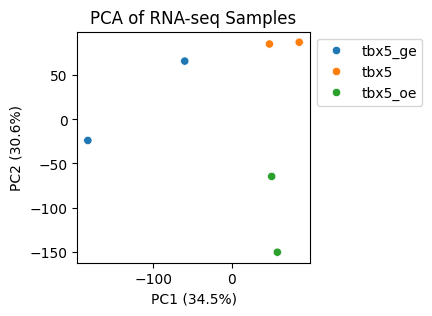

In [ ]:
scaler = StandardScaler()
scaled_table = scaler.fit_transform(log_transformed_counts.T)
pca = PCA()
pca_result_matrix = pca.fit_transform(scaled_table)
np.shape(pca_result_matrix)

plot_df = pd.DataFrame({
 "PC1": pca_result_matrix[:, 0],
 "PC2": pca_result_matrix[:, 1],
 "condition": metadata["condition"].values
})

plt.figure(figsize=(3, 3))

sns.scatterplot(
data=plot_df,
x="PC1", y="PC2",
hue="condition"
)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA of RNA-seq Samples")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

## Differential gene expression

Now you can perform differential gene expression analysis using the DEseq2 method. This method allows to find genes with significant expression differences (up- or downregulated) between two conditions.
- Your goal is to investigate the effect of the perturbation on cardiomyocyte differentiation. Which samples do you want to compare? Choose two conditions.
- Build your DEseq object(s) and run the analysis. *Make sure you use the raw filtered counts for this (not the counts per million normalized counts used for PCA), since DEseq does it's own internal normalization method.*
- Look at the results of you analysis. What information do the rows and columns of the DEseq result mean?

**Solution**<br/>
We need to compare either the overexpressed (tbx5_oe) or gene-edited (tbx5_ge) samples with a control (tbx5). The rows are the gene names and the columns show the statistical differential expression results.
- baseMean: mean normalized expression across all samples.
- log2FoldChange: log₂ of the estimated fold change between conditions.
- lfcSE: standard error of the log2FoldChange estimate.
- stat: Wald test statistic (log2FoldChange / lfcSE).
- pvalue: p-value for H₀: log2FoldChange = 0.
- padj: p-value adjusted for multiple testing (FDR, e.g. Benjamini–Hochberg).

### ANSWER CODE OVEREXPRESSION VS CONTROL

In [ ]:
dds_oe = DeseqDataSet(counts=counts.T, metadata=metadata, design_factors="condition")
dds_oe.deseq2()
stat_res_oe = DeseqStats(
    dds_oe,
    contrast=("condition","tbx5_oe","tbx5")
)
stat_res_oe.summary()
res_df_oe = stat_res_oe.results_df

Fitting size factors...
... done in 0.03 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 32.75 seconds.

Fitting dispersion trend curve...
... done in 0.72 seconds.

Fitting MAP dispersions...
... done in 37.50 seconds.

Fitting LFCs...
... done in 22.92 seconds.

Calculating cook's distance...
... done in 0.01 seconds.

Replacing 0 outlier genes.

Running Wald tests...


Log2 fold change & Wald test p-value: condition tbx5_oe vs tbx5
                  baseMean  log2FoldChange     lfcSE      stat    pvalue  \
WASH7P          443.953609       -0.035555  0.451601 -0.078732  0.937246   
MIR6859-1         1.872386        0.643619  2.354705  0.273333  0.784597   
LOC124900384      9.034005       -0.151071  1.154206 -0.130887  0.895864   
LOC729737       212.921765       -2.085322  0.508563 -4.100419  0.000041   
LOC100996442    189.966472       -0.438729  0.526367 -0.833504  0.404561   
...                    ...             ...       ...       ...       ...   
ND4           97900.414350       -0.493245  0.505089 -0.976551  0.328791   
ND5           64250.061181       -0.436124  0.514999 -0.846845  0.397082   
ND6           19254.874203       -0.529143  0.506128 -1.045474  0.295804   
CYTB          50074.203112       -0.371464  0.493845 -0.752187  0.451939   
TRNP           1114.165458        0.468073  0.480327  0.974488  0.329814   

                  padj 

... done in 6.47 seconds.



### ANSWER CODE DOWNREGULATION VS CONTROL

In [ ]:
dds_ge = DeseqDataSet(counts=counts.T, metadata= metadata, design_factors="condition")
dds_ge.deseq2()
stat_res_ge = DeseqStats(
    dds_ge,
    contrast=("condition","tbx5_ge","tbx5")
)
stat_res_ge.summary()
res_df_ge = stat_res_ge.results_df

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.01 seconds.

Fitting dispersions...
... done in 30.40 seconds.

Fitting dispersion trend curve...
... done in 0.82 seconds.

Fitting MAP dispersions...
... done in 34.82 seconds.

Fitting LFCs...
... done in 21.85 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 0 outlier genes.

Running Wald tests...


Log2 fold change & Wald test p-value: condition tbx5_ge vs tbx5
                  baseMean  log2FoldChange     lfcSE      stat    pvalue  \
WASH7P          443.953609       -0.174682  0.452340 -0.386174  0.699368   
MIR6859-1         1.872386        1.873317  2.279679  0.821746  0.411221   
LOC124900384      9.034005       -1.667438  1.243654 -1.340757  0.179999   
LOC729737       212.921765       -1.235557  0.504862 -2.447317  0.014392   
LOC100996442    189.966472       -0.321613  0.526896 -0.610393  0.541602   
...                    ...             ...       ...       ...       ...   
ND4           97900.414350       -1.594850  0.505103 -3.157472  0.001591   
ND5           64250.061181       -1.856058  0.515028 -3.603796  0.000314   
ND6           19254.874203       -2.087116  0.506246 -4.122734  0.000037   
CYTB          50074.203112       -1.480815  0.493874 -2.998367  0.002714   
TRNP           1114.165458       -2.352658  0.484564 -4.855208  0.000001   

                  padj 

... done in 6.85 seconds.



- Now get the significantly upregulated and downregulated genes from this dataframe with a log2 fold change bigger than 2. Are there more genes that are upregulated or downregulated? _Tip: to get an overview in one figure, you can plot the upregulated and downregulated genes in a volcano plot._

**Solution**<br/>
tbx5_oe: there are more genes downregulated (539) than upregulated (392). <br/>
tbx5_ge: there are more genes downregulated (1052) than upregulated (389).

### ANSWER CODE OVEREXPRESSION VS CONTROL

In [ ]:
upregulated_genes_oe = res_df_oe[(res_df_oe["log2FoldChange"] > 2) & (res_df_oe["padj"] < 0.05)]
upregulated_genes_oe

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
LINC01770,29.622019,3.681060,0.892376,4.125012,0.000037,0.001892
HES5,19.869682,7.034789,1.968678,3.573357,0.000352,0.010294
LOC124903827,230.615818,3.050596,0.761040,4.008456,0.000061,0.002758
PRDM16,544.285322,2.243694,0.676317,3.317519,0.000908,0.020347
LOC124903828,22.527103,2.605947,0.862061,3.022927,0.002503,0.041123
...,...,...,...,...,...,...
ATP1B4,14.798220,4.208532,1.394276,3.018435,0.002541,0.041524
ZIC3,132.048619,5.082075,1.182028,4.299454,0.000017,0.001065
SOX3,109.859081,4.653391,1.060990,4.385894,0.000012,0.000787
GABRQ,15.726915,5.869845,1.736967,3.379365,0.000727,0.017313


In [ ]:
downregulated_genes_oe = res_df_oe[(res_df_oe["log2FoldChange"] < -2) & (res_df_oe["padj"] < 0.05)]
downregulated_genes_oe

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
LOC729737,212.921765,-2.085322,0.508563,-4.100419,4.124034e-05,2.044664e-03
LOC100132287,16.736439,-3.935306,1.131729,-3.477251,5.065825e-04,1.331907e-02
LOC284600,304.242953,-2.659591,0.622419,-4.272989,1.928701e-05,1.168731e-03
LINC02593,119.203850,-3.378177,0.690644,-4.891344,1.001499e-06,1.172798e-04
LOC107985728,243.697342,-3.572923,0.723289,-4.939829,7.819124e-07,9.567400e-05
...,...,...,...,...,...,...
TXLNGY,486.709350,-11.991910,2.443795,-4.907084,9.244025e-07,1.095962e-04
KDM5D,1354.596160,-12.157775,1.519090,-8.003326,1.211025e-15,1.444753e-12
LOC105377224,15.571114,-7.701108,2.627859,-2.930563,3.383478e-03,4.998749e-02
EIF1AY,712.431330,-12.065268,2.425272,-4.974811,6.531138e-07,8.366870e-05


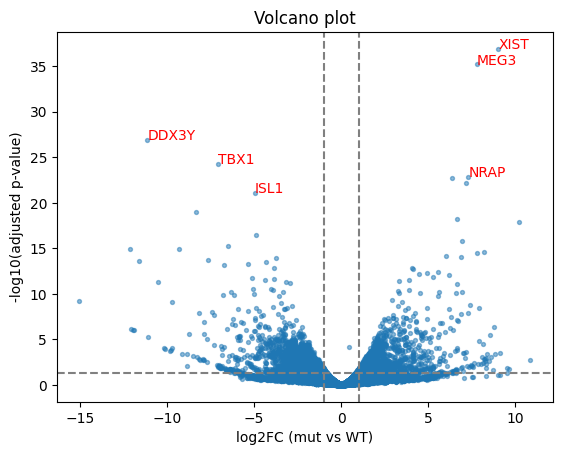

In [ ]:
plt.scatter(res_df_oe.log2FoldChange, -np.log10(res_df_oe.pvalue), s=8, alpha=0.5)

plt.axhline(-np.log10(0.05), ls="--", color="grey")
plt.axvline(1, ls="--", color="grey")
plt.axvline(-1, ls="--", color="grey")

plt.xlabel("log2FC (mut vs WT)")
plt.ylabel("-log10(adjusted p-value)")
plt.title(f"Volcano plot")

up_oe = res_df_oe[res_df_oe.log2FoldChange > 1].nsmallest(3, "pvalue")
down_oe = res_df_oe[res_df_oe.log2FoldChange < -1].nsmallest(3, "pvalue")

for gene, r in up_oe.iterrows():
  plt.text(r.log2FoldChange, -np.log10(r.pvalue), gene,
  fontsize=10, color="red")
for gene, r in down_oe.iterrows():
  plt.text(r.log2FoldChange, -np.log10(r.pvalue), gene,
  fontsize=10, color="red")

plt.show()

### ANSWER CODE DOWNREGULATION VS CONTROL

In [ ]:
upregulated_genes_ge = res_df_ge[(res_df_ge["log2FoldChange"] > 2) & (res_df_ge["padj"] < 0.05)]
upregulated_genes_ge

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
PLEKHN1,21.050226,3.024530,0.903657,3.346987,0.000817,0.012587
TNFRSF9,193.416887,4.427395,1.143500,3.871793,0.000108,0.002644
LOC124903834,28.517730,2.374908,0.839227,2.829875,0.004657,0.043959
ERRFI1,4156.847450,2.267711,0.708311,3.201574,0.001367,0.018769
RBP7,43.885849,2.612693,0.861195,3.033800,0.002415,0.028115
...,...,...,...,...,...,...
PIM2,412.052715,2.103439,0.664979,3.163167,0.001561,0.020722
TCEAL5,23.975164,3.297139,1.052961,3.131302,0.001740,0.022415
TCEAL7,145.014799,3.271191,0.713048,4.587618,0.000004,0.000177
ZIC3,132.048619,5.218380,1.182205,4.414107,0.000010,0.000367


In [ ]:
downregulated_genes_ge = res_df_ge[(res_df_ge["log2FoldChange"] < -2) & (res_df_ge["padj"] < 0.05)]
downregulated_genes_ge

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
LOC284600,304.242953,-2.388037,0.622284,-3.837536,0.000124,0.002953
LINC02593,119.203850,-2.750118,0.684543,-4.017454,0.000059,0.001604
LOC107985728,243.697342,-2.715845,0.718494,-3.779914,0.000157,0.003461
MMP23B,672.810903,-2.500791,0.706062,-3.541888,0.000397,0.007321
MEGF6,4166.765427,-2.678703,0.679125,-3.944343,0.000080,0.002067
...,...,...,...,...,...,...
ARHGAP4,137.921579,-2.102679,0.543005,-3.872302,0.000108,0.002642
RENBP,210.497972,-2.092206,0.692270,-3.022241,0.002509,0.028886
TMEM187,171.407402,-2.009192,0.523751,-3.836157,0.000125,0.002953
ND6,19254.874203,-2.087116,0.506246,-4.122734,0.000037,0.001096


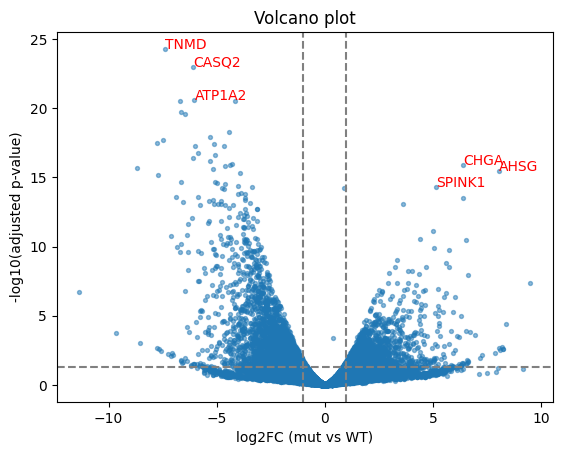

In [ ]:
plt.scatter(res_df_ge.log2FoldChange, -np.log10(res_df_ge.pvalue), s=8, alpha=0.5)

plt.axhline(-np.log10(0.05), ls="--", color="grey")
plt.axvline(1, ls="--", color="grey")
plt.axvline(-1, ls="--", color="grey")

plt.xlabel("log2FC (mut vs WT)")
plt.ylabel("-log10(adjusted p-value)")
plt.title(f"Volcano plot")

up_ge = res_df_ge[res_df_ge.log2FoldChange > 1].nsmallest(3, "pvalue")
down_ge = res_df_ge[res_df_ge.log2FoldChange < -1].nsmallest(3, "pvalue")

for gene, r in up_ge.iterrows():
  plt.text(r.log2FoldChange, -np.log10(r.pvalue), gene,
  fontsize=10, color="red")
for gene, r in down_ge.iterrows():
  plt.text(r.log2FoldChange, -np.log10(r.pvalue), gene,
  fontsize=10, color="red")

plt.show()

- Take the dataframe of your DESeq2 results (res_df) and sort the values by the significant p-adjusted value (padj). Then take the top 10 genes names from the sorted dataframe (_hint: top10 = res_df.head(10).index_). Print this top 10 to know which genes you would like to visualize in your heatmap.

### ANSWER CODE OVEREXPRESSION VS CONTROL

In [ ]:
res_df_oe = res_df_oe.sort_values('padj')
top10_oe = res_df_oe.head(10).index
top10_oe

Index(['XIST', 'MEG3', 'DDX3Y', 'TBX1', 'NRAP', 'TRDN-AS1', 'BRINP3', 'ISL1',
       'AFP', 'USP6'],
      dtype='object')

### ANSWER CODE DOWNREGULATION VS CONTROL

In [ ]:
res_df_ge = res_df_ge.sort_values('padj')
top10_ge = res_df_ge.head(10).index
top10_ge

Index(['TNMD', 'CASQ2', 'ATP1A2', 'HRH2', 'PPP1R1A', 'ASPN', 'PPP1R3A',
       'CACNA1G', 'KIAA0319', 'LOC107986182'],
      dtype='object')

- Now create a list of genes for your heatmap, also add the overexpressed/gene-edited gene in this list and perform your visualization. Can you confirm whether the authors managed to succesfully knockdown or overexpress our gene of interest?
- Are there any genes that you can link to gain/loss of cardiac identity?

**Solution**<br/>
- Yes, you can see a higher expression of TBX5 in the overexpressed samples compared to the control and gene-edited samples, so the overexpression worked. However, they did not manage to fully knockout TBX5 with gene-editing.<br/><br/>
- tbx5_oe: increased NRAP (myofibril assembly and cytoskeletal organization) and TRDN-AS1 (regulation of the triadin/calcium-handling locus) indicate enhanced cardiomyocyte structural organization and excitation–contraction–related programs. Elevated XIST (X-chromosome inactivation) and MEG3 (developmental and epigenetic lncRNA) suggest altered chromatin and transcriptional regulation. Increased BRINP3 (differentiation-associated signaling) and USP6 (ubiquitin-mediated cellular remodeling) reflect broader regulatory and cellular adaptation to forced TBX5 expression. Reduced ISL1 (cardiac progenitor transcription factor) and TBX1 (early cardiac/mesoderm patterning factor) indicate loss of progenitor and alternative developmental identities, while decreased AFP (early embryonic/endoderm marker) supports increased lineage restriction. DDX3Y (Y-linked RNA helicase) is reduced but not lineage-informative. <br/><br/>
- tbx5_ge: reduced CASQ2 (sarcoplasmic reticulum calcium buffering), CACNA1G (T-type calcium channel), ATP1A2 (Na⁺/K⁺ ATPase), and HRH2 (cAMP-linked signaling receptor) indicates impaired calcium handling, membrane excitability, and cardiomyocyte signaling. Decreased PPP1R1A and PPP1R3A (regulators of phosphatase activity and glycogen metabolism) suggest disrupted intracellular signaling and energy regulation. Downregulation of TNMD and ASPN (extracellular matrix and mesenchymal-associated proteins) reflects altered structural or cell–matrix interactions. KIAA0319 (cellular trafficking/adhesion-associated) and LOC107986182 (poorly characterized transcript) likely represent nonspecific transcriptional effects.
Overall, TBX5 knockdown primarily suppresses genes involved in cardiomyocyte functional competence and cellular homeostasis.

### ANSWER CODE OVEREXPRESSION VS CONTROL

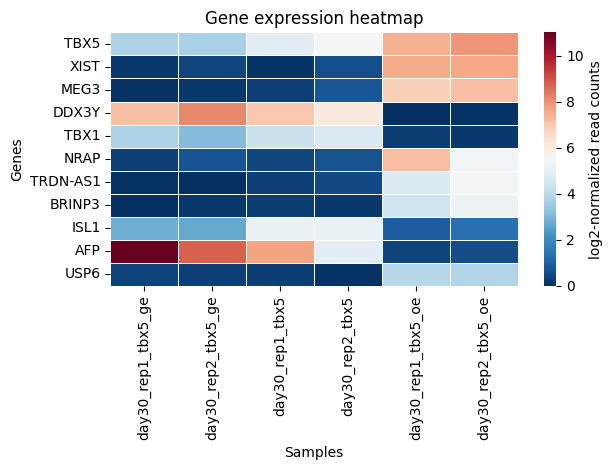

In [ ]:
gene_list_oe = ['TBX5', 'XIST', 'MEG3', 'DDX3Y', 'TBX1', 'NRAP', 'TRDN-AS1', 'BRINP3', 'ISL1', 'AFP', 'USP6']

sns.heatmap(
log_transformed_counts.loc[gene_list_oe],
cmap="RdBu_r",
linecolor = "white",
linewidth = 0.5,
cbar_kws={"label": "log2-normalized read counts"}
)
plt.title("Gene expression heatmap")
plt.xlabel("Samples")
plt.ylabel("Genes")
plt.tight_layout()
plt.show()


### ANSWER CODE DOWNREGULATION VS CONTROL

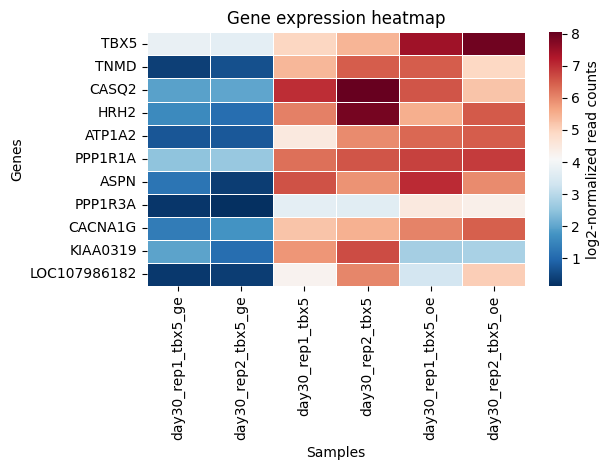

In [ ]:
gene_list_ge = ['TBX5', 'TNMD', 'CASQ2', 'HRH2', 'ATP1A2', 'PPP1R1A', 'ASPN', 'PPP1R3A', 'CACNA1G', 'KIAA0319', 'LOC107986182']

sns.heatmap(
log_transformed_counts.loc[gene_list_ge],
cmap="RdBu_r",
linecolor = "white",
linewidth = 0.5,
cbar_kws={"label": "log2-normalized read counts"}
)
plt.title("Gene expression heatmap")
plt.xlabel("Samples")
plt.ylabel("Genes")
plt.tight_layout()
plt.show()


# Gene Ontology enrichment

Now, you can start interpreting the lists of genes you get from the DEseq analysis and learn if there are any biological pathways that are effected by the TBX5 mutation.
- Use the cheat sheet to perform a GO enrichment analysis on the downregulated and upregulated genes. Which biological processes are upregulated and downregulated?
- Can you find scientific evidence in literature that these processes are regulated by TBX5?

**Solution**<br/>
Biological processes affected by TBX5 perturbation are predominantly related to cardiac contraction, conduction, and cardiac muscle development, consistent with the established role of TBX5 in cardiac septation, chamber specification, and conduction system formation. Gain- and loss-of-function studies in hiPSC-derived cardiomyocytes have shown that TBX5 reshapes gene networks controlling electrophysiological properties and atrial fate, which is reflected in the enrichment of cardiac conduction and contractile pathways. In parallel, enrichment of neuronal development and synapse-related pathways likely reflects shared transcriptional programs between cardiac conduction cells and neuronal lineages, rather than true neurogenesis. Upon TBX5 loss, additional upregulation of heat acclimation and endoplasmic-reticulum stress pathways indicates activation of generic cellular stress and calcium-handling responses, suggesting that TBX5 depletion destabilizes cardiac lineage identity and triggers compensatory homeostatic signaling.

- https://doi.org/10.1016/bs.ctdb.2016.08.008

### ANSWER CODE OVEREXPRESSION VS CONTROL

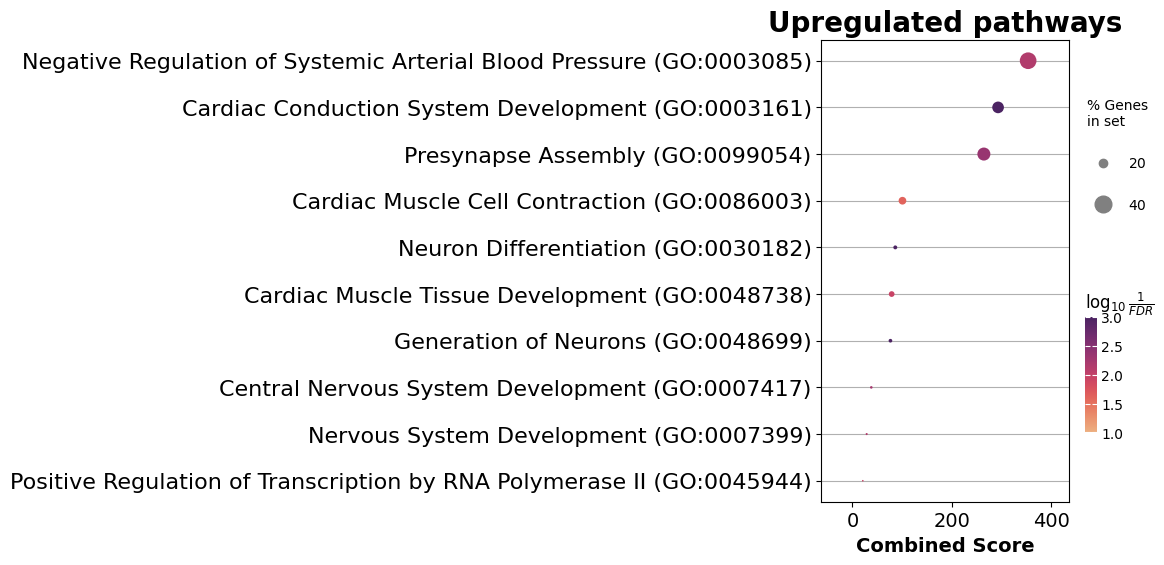

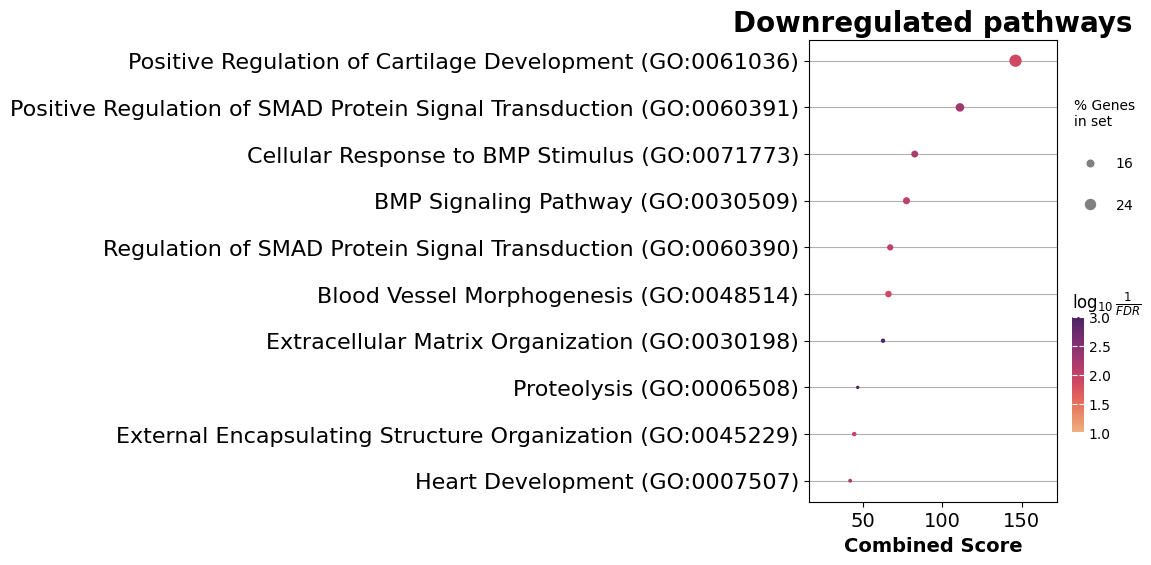

In [ ]:
up_oe   = upregulated_genes_oe.index.tolist()
down_oe = downregulated_genes_oe.index.tolist()

enr_up_oe = gseapy.enrichr(up_oe,
                        gene_sets=["GO_Biological_Process_2025"],
                        organism="Human", cutoff=0.05)
gseapy.plot.dotplot(enr_up_oe.res2d, title=f"Upregulated pathways", cmap="flare", top_term=10)
plt.show()

enr_down_oe = gseapy.enrichr(down_oe,
                          gene_sets=["GO_Biological_Process_2025"],
                          organism="Human", cutoff=0.05)
gseapy.plot.dotplot(enr_down_oe.res2d, title=f"Downregulated pathways", cmap="flare", top_term=10)
plt.show()

### ANSWER CODE DOWNREGULATION VS CONTROL

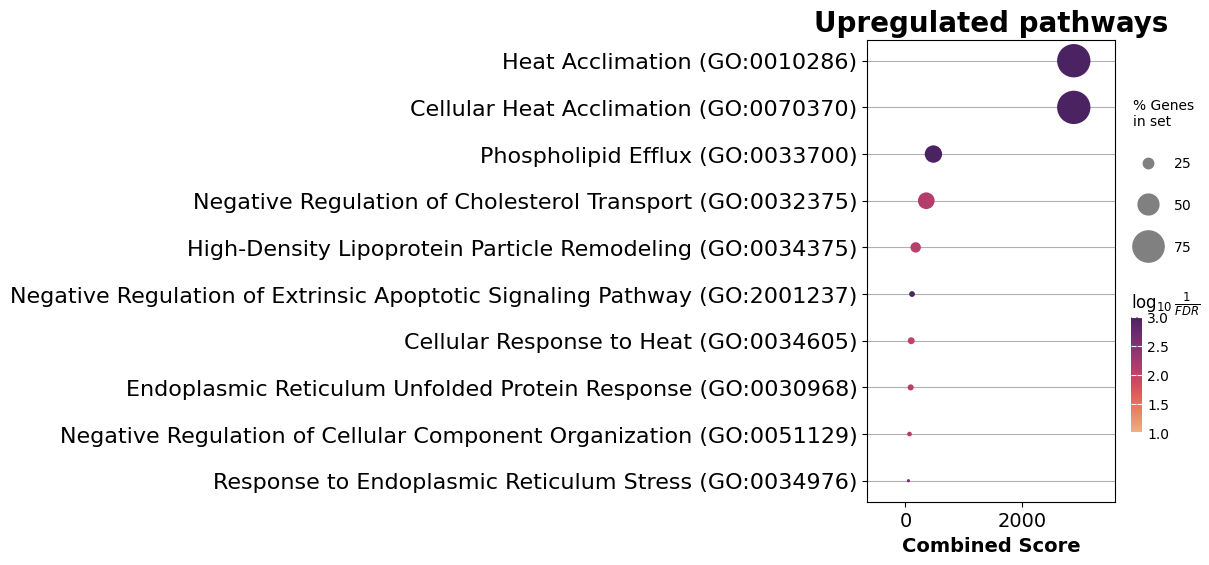

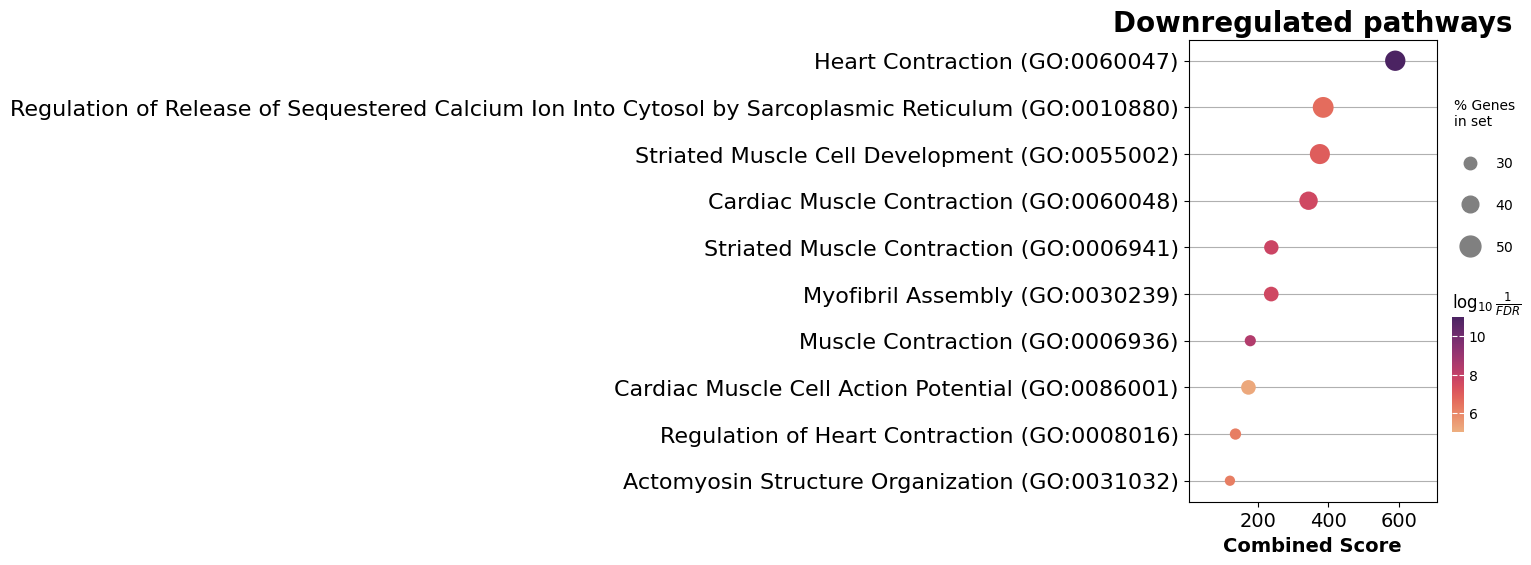

In [ ]:
up_ge   = upregulated_genes_ge.index.tolist()
down_ge = downregulated_genes_ge.index.tolist()

enr_up_ge = gseapy.enrichr(up_ge,
                        gene_sets=["GO_Biological_Process_2025"],
                        organism="Human", cutoff=0.05)
gseapy.plot.dotplot(enr_up_ge.res2d, title=f"Upregulated pathways", cmap="flare", top_term=10)
plt.show()

enr_down_ge = gseapy.enrichr(down_ge,
                          gene_sets=["GO_Biological_Process_2025"],
                          organism="Human", cutoff=0.05)
gseapy.plot.dotplot(enr_down_ge.res2d, title=f"Downregulated pathways", cmap="flare", top_term=10)
plt.show()